# 10 · Regression *and* classification in one network

"The test is on training a network for regression or classification — or even both." *Both at once* means a **multi-task** network: one shared body, two outputs, two losses added together. Nothing in it is new — it is notebooks 06 and 07 running in the same loop — but there are a few places where the two halves can trip over each other.

Data: `houses.csv` again, now with **two labels per house**: `price` (regression, k€) and `sold_fast` (binary: sold within 30 days).

---
## Theory in 60 seconds

```
                         ┌─> head_price: Linear(16, 1)            -> MSE          (target: float (batch, 1))
x ─> shared trunk (MLP) ─┤
                         └─> head_sold:  Linear(16, 1) -> logit   -> BCEWithLogits (target: float (batch, 1))

total loss = loss_price + λ · loss_sold          one backward(), one optimizer.step()
```

- The **trunk** learns features useful for both tasks; each **head** is just the output layer you already know for its task.
- `backward()` on the *sum* sends gradients from both losses into the shared trunk — no special machinery.
- **Loss scale matters.** The optimiser minimises the sum; a loss that is numerically 10 000× larger dominates completely. Bring the losses to comparable size: standardise the regression target and/or weight the terms with `λ`.
- Each task keeps its own metric (RMSE in k€; accuracy), and predictions for the regression head must be **un-standardised** before you report them.

In [1]:
import sys; sys.path.insert(0, "..")
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from dnd_utils import check, load_houses

d = load_houses()
X_train, y_train, s_train = d["X_train"], d["y_train"], d["s_train"]     # (720, 13), price (720,), sold_fast (720,) 0.0/1.0
X_val, y_val, s_val = d["X_val"], d["y_val"], d["s_val"]
X_test, y_test, s_test = d["X_test"], d["y_test"], d["s_test"]
print(X_train.shape, y_train[:4], s_train[:8], "| fraction sold fast:", s_train.mean().round(3))

(720, 13) [134.  263.3 131.1 379.3] [0. 0. 0. 1. 0. 0. 0. 0.] | fraction sold fast: 0.318


---
## Exercise 10.1 · How different are the two loss scales?

Before any training: an untrained network outputs roughly 0 for the price and a logit of roughly 0 for `sold_fast`. Compute what the two losses are in that situation:

- `mse_at_zero`: MSE of predicting 0 for every training price,
- `bce_at_zero`: BCE of predicting logit 0 (p = 0.5) for every training label,
- `ratio = mse_at_zero / bce_at_zero`.

In [2]:
mse_at_zero = float((y_train ** 2).mean())          # (0 - y)^2 averaged  = mean^2 + variance
bce_at_zero = float(np.log(2))                      # -ln 0.5 for every sample, whatever its label
ratio = mse_at_zero / bce_at_zero
print(mse_at_zero, bce_at_zero, ratio)

50182.8828125 0.6931471805599453 72398.59617110575


In [3]:
check("mse_at_zero ≈ 50 000", lambda: abs(mse_at_zero - float((y_train.astype(np.float64) ** 2).mean())) < 1)
check("bce_at_zero = ln 2", lambda: abs(bce_at_zero - np.log(2)) < 1e-6)
check("ratio", lambda: abs(ratio - mse_at_zero / np.log(2)) < 1)

✅ mse_at_zero ≈ 50 000
✅ bce_at_zero = ln 2
✅ ratio


True

If you simply trained on `MSE + BCE` with these raw targets, what would the network do about the classification task?

**Answer.** Practically nothing. The total loss is ~70 000× dominated by the price term, and so are the gradients in the shared trunk: any change that lowers the MSE by a tiny fraction outweighs even a perfect solution of the classification task. The classification head would stay near its initial `ln 2` for a long time, and when the price loss finally becomes small (a few hundred) it is still hundreds of times larger than the BCE. The fix is to make the two terms comparable.

---
## Exercise 10.2 · Standardise the regression target

Compute `y_mean` and `y_std` from the **training** prices and create `yz_train`, `yz_val`, `yz_test` (standardised prices). Then repeat the computation of 10.1 for the standardised target: `mse_z_at_zero`.

In [4]:
y_mean = y_train.mean()
y_std = y_train.std()
yz_train = (y_train - y_mean) / y_std
yz_val = (y_val - y_mean) / y_std             # training statistics for every split
yz_test = (y_test - y_mean) / y_std
mse_z_at_zero = float((yz_train ** 2).mean())
print(y_mean, y_std, mse_z_at_zero)

205.3386 89.54854 1.0


In [5]:
check("y_mean, y_std from the training set", lambda: abs(y_mean - d["y_train"].mean()) < 1e-3 and abs(y_std - d["y_train"].std()) < 1e-3)
check("val/test use the training statistics", lambda: np.allclose(yz_val, (d["y_val"] - d["y_train"].mean()) / d["y_train"].std(), atol=1e-5) and np.allclose(yz_test, (d["y_test"] - d["y_train"].mean()) / d["y_train"].std(), atol=1e-5))
check("MSE of predicting 0 is now exactly 1 (why?)", lambda: abs(mse_z_at_zero - 1.0) < 1e-3)

✅ y_mean, y_std from the training set
✅ val/test use the training statistics
✅ MSE of predicting 0 is now exactly 1 (why?)


True

With a standardised target, "predict 0" **is** the mean-baseline and its MSE is the variance, i.e. 1. A convenient side effect: the standardised MSE reads directly as "fraction of the variance not explained" (`1 − R²`). Both losses now start near 1 and 0.69 — comparable.

---
## Exercise 10.3 · A dataset with two labels

Write `TwoTaskDataset(x, y_price, y_sold)`: `__getitem__` returns **three** tensors so that a loader yields `(batch, 13)`, `(batch, 1)`, `(batch, 1)`, all `float32`. Create the three loaders (batch size 32) using the **standardised** prices.

In [6]:
class TwoTaskDataset(Dataset):
    def __init__(self, x, y_price, y_sold):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.yp = torch.tensor(y_price, dtype=torch.float32)
        self.ys = torch.tensor(y_sold, dtype=torch.float32)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        return self.xs[idx], self.yp[idx, None], self.ys[idx, None]       # a tuple of any length is fine

loader_train = DataLoader(TwoTaskDataset(X_train, yz_train, s_train), batch_size=32, shuffle=True)
loader_val = DataLoader(TwoTaskDataset(X_val, yz_val, s_val), batch_size=32, shuffle=True)
loader_test = DataLoader(TwoTaskDataset(X_test, yz_test, s_test), batch_size=32, shuffle=False)

In [7]:
check("a batch is a triple", lambda: len(next(iter(loader_train))) == 3)
check("shapes (32, 13), (32, 1), (32, 1)", lambda: [tuple(t.shape) for t in next(iter(loader_train))] == [(32, 13), (32, 1), (32, 1)])
check("all float32", lambda: all(t.dtype == torch.float32 for t in next(iter(loader_train))))
check("the price target is standardised", lambda: abs(torch.cat([b[1] for b in loader_train]).mean().item()) < 1e-3)
check("the sold target is 0/1", lambda: set(torch.cat([b[2] for b in loader_train]).unique().tolist()) == {0.0, 1.0})

✅ a batch is a triple
✅ shapes (32, 13), (32, 1), (32, 1)
✅ all float32
✅ the price target is standardised
✅ the sold target is 0/1


True

---
## Exercise 10.4 · The two-headed model

Write `TwoHeadMLP(n_inputs)`:

- `trunk`: `n_inputs → 32 → 16`, ReLU after both layers,
- `head_price`: `16 → 1` (no activation),
- `head_sold`: `16 → 1` (a logit, no activation),
- `forward(x)` returns the **tuple** `(price_pred, sold_logit)`.

How many parameters does it have (by hand first)?

In [8]:
n_params_by_hand = (13 * 32 + 32) + (32 * 16 + 16) + (16 + 1) + (16 + 1)        # 448 + 528 + 17 + 17 = 1010

class TwoHeadMLP(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU())
        self.head_price = nn.Linear(16, 1)
        self.head_sold = nn.Linear(16, 1)

    def forward(self, x):
        h = self.trunk(x)                               # shared features, (batch, 16)
        return self.head_price(h), self.head_sold(h)    # two outputs, each (batch, 1)

In [9]:
_out = None
try: _out = TwoHeadMLP(13)(torch.randn(5, 13))
except Exception: pass
check("forward returns two tensors", lambda: isinstance(_out, tuple) and len(_out) == 2)
check("each of shape (5, 1)", lambda: _out[0].shape == (5, 1) and _out[1].shape == (5, 1))
check("1010 parameters", lambda: sum(p.numel() for p in TwoHeadMLP(13).parameters()) == 1010 == n_params_by_hand)
check("both heads are registered sub-modules", lambda: {"head_price", "head_sold", "trunk"} <= {n for n, _ in TwoHeadMLP(13).named_children()})

✅ forward returns two tensors
✅ each of shape (5, 1)
✅ 1010 parameters
✅ both heads are registered sub-modules


True

---
## Exercise 10.5 · Train on the combined loss

Train a fresh `TwoHeadMLP` for 80 epochs with `Adam(lr=0.003)` on

`loss = MSE(price_pred, price_z) + LAMBDA · BCEWithLogits(sold_logit, sold)`, with `LAMBDA = 1.0`.

Per epoch record, on the **validation** set: `val_total`, `val_mse`, `val_bce`, `val_acc` (lists), and `train_total` on the training set.

<details><summary>Hint</summary>

A loop over the loader now unpacks three things: `for xb, yp, ys in loader:`. The model call unpacks two: `price_pred, sold_logit = model(xb)`. Everything else is the loop you know. Only **one** `backward()` — on the sum.
</details>

In [10]:
LAMBDA = 1.0
mse_fn, bce_fn = nn.MSELoss(), nn.BCEWithLogitsLoss()

def run_epoch(model, loader, optimizer=None):
    """Returns the epoch means of (total loss, mse, bce, accuracy). Trains if an optimizer is given."""
    training = optimizer is not None
    model.train() if training else model.eval()
    stats = []
    with torch.set_grad_enabled(training):
        for xb, yp, ys in loader:
            price_pred, sold_logit = model(xb)
            mse = mse_fn(price_pred, yp)
            bce = bce_fn(sold_logit, ys)
            loss = mse + LAMBDA * bce                         # one scalar that depends on both heads and the trunk
            if training:
                optimizer.zero_grad()
                loss.backward()                               # gradients of BOTH tasks flow into the trunk
                optimizer.step()
            acc = ((sold_logit > 0).float() == ys).float().mean()
            stats.append([loss.item(), mse.item(), bce.item(), acc.item()])
    return np.mean(stats, axis=0)

torch.manual_seed(0)
model = TwoHeadMLP(X_train.shape[1])
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
train_total, val_total, val_mse, val_bce, val_acc = [], [], [], [], []
for epoch in range(80):
    tr = run_epoch(model, loader_train, optimizer)
    va = run_epoch(model, loader_val)
    train_total.append(tr[0]); val_total.append(va[0]); val_mse.append(va[1]); val_bce.append(va[2]); val_acc.append(va[3])
    if epoch % 10 == 0 or epoch == 79:
        print(f"epoch {epoch:2d}  train total {tr[0]:.3f} | val total {va[0]:.3f}  mse {va[1]:.3f}  bce {va[2]:.3f}  acc {va[3]:.3f}")

epoch  0  train total 1.354 | val total 1.053  mse 0.429  bce 0.624  acc 0.676


epoch 10  train total 0.521 | val total 0.583  mse 0.041  bce 0.541  acc 0.742


epoch 20  train total 0.496 | val total 0.581  mse 0.032  bce 0.549  acc 0.742


epoch 30  train total 0.478 | val total 0.585  mse 0.028  bce 0.557  acc 0.754


epoch 40  train total 0.467 | val total 0.624  mse 0.032  bce 0.592  acc 0.707


epoch 50  train total 0.460 | val total 0.648  mse 0.043  bce 0.605  acc 0.738


epoch 60  train total 0.439 | val total 0.690  mse 0.033  bce 0.658  acc 0.734


epoch 70  train total 0.426 | val total 0.750  mse 0.032  bce 0.717  acc 0.715


epoch 79  train total 0.408 | val total 0.740  mse 0.031  bce 0.709  acc 0.727


In [11]:
check("80 epochs recorded in all five lists", lambda: all(len(l) == 80 for l in (train_total, val_total, val_mse, val_bce, val_acc)))
check("total = mse + LAMBDA * bce", lambda: len(val_total) == 80 and np.allclose(np.array(val_total), np.array(val_mse) + LAMBDA * np.array(val_bce), atol=1e-4))
check("the regression task was learned (standardised MSE < 0.08)", lambda: val_mse[-1] < 0.08)
check("the classification task was learned (best validation BCE clearly below ln 2)", lambda: min(val_bce) < 0.6)

✅ 80 epochs recorded in all five lists
✅ total = mse + LAMBDA * bce
✅ the regression task was learned (standardised MSE < 0.08)
✅ the classification task was learned (best validation BCE clearly below ln 2)


True

Plot three panels: total loss (train and validation), the two validation loss components, and the validation accuracy.

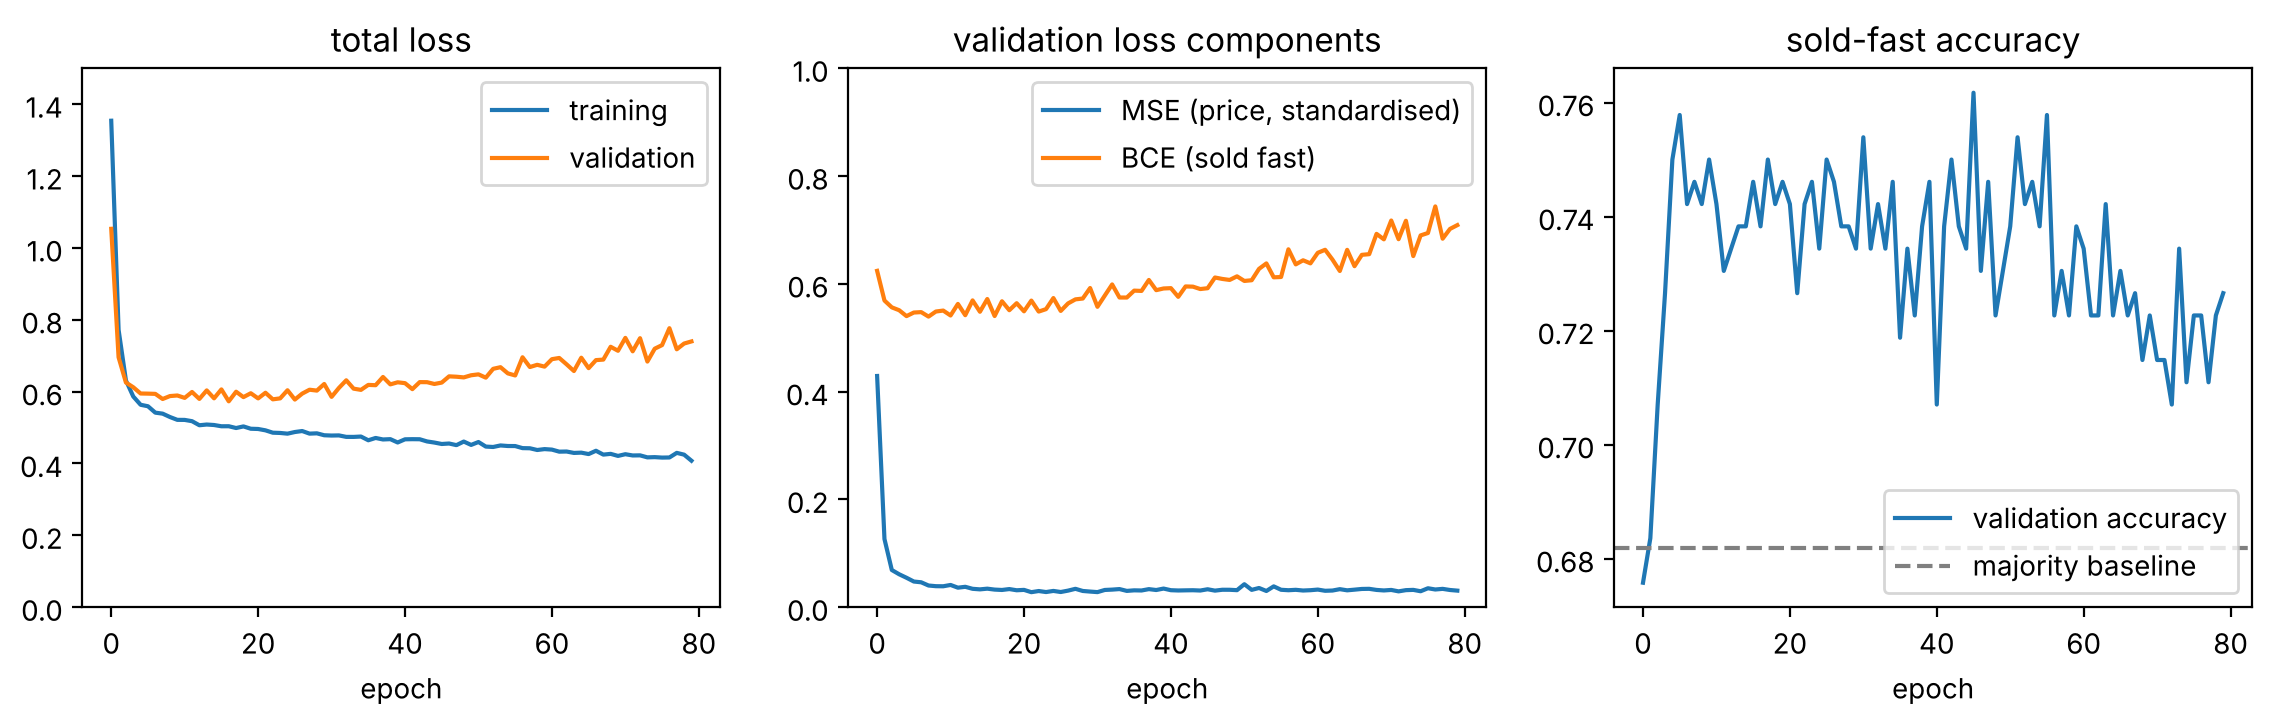

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(train_total, label="training"); axes[0].plot(val_total, label="validation")
axes[0].set_title("total loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylim(0, 1.5); axes[0].legend()
axes[1].plot(val_mse, label="MSE (price, standardised)"); axes[1].plot(val_bce, label="BCE (sold fast)")
axes[1].set_title("validation loss components"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1); axes[1].legend()
axes[2].plot(val_acc, label="validation accuracy"); axes[2].axhline(1 - s_train.mean(), color="gray", ls="--", label="majority baseline")
axes[2].set_title("sold-fast accuracy"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.show()

Look at the middle panel. The two tasks do **not** behave the same over time. Describe what each validation component does after roughly epoch 15–20, why that can happen, and name two things you could do about it.

**Answer.** The price MSE keeps improving slowly (or stays flat), while the sold-fast BCE reaches its minimum early and then **rises** — the classification head (and the trunk features it uses) starts to over-fit: `sold_fast` is a noisy label that the inputs only partly explain, so there is little real signal and a lot of noise to memorise. Tasks in a multi-task network generally over-fit at different speeds. Options: **early stopping** on the total validation loss (the blank-page drill below) or on the task you care about most; a smaller `LAMBDA` or regularisation (weight decay, dropout) to slow down the over-fitting task; or, if one task matters more, choosing the checkpoint by that task's validation metric.

---
## Exercise 10.6 · Evaluate both tasks on the test set — in real units

Compute on the full test set:

- `price_pred_keur`: predicted prices **in k€**, shape `(240, 1)` (undo the standardisation!)
- `test_rmse_keur`: RMSE in k€
- `baseline_rmse_keur`: RMSE of always predicting the training mean price
- `test_acc` for `sold_fast`, and `baseline_acc` (majority class of the training set)

In [13]:
model.eval()
pp, sl, st = [], [], []
with torch.no_grad():
    for xb, yp, ys in loader_test:
        price_pred, sold_logit = model(xb)
        pp.append(price_pred); sl.append(sold_logit); st.append(ys)
pp, sl, st = torch.cat(pp), torch.cat(sl), torch.cat(st)

price_pred_keur = pp * float(y_std) + float(y_mean)                       # invert z = (y - mean) / std
price_true_keur = torch.tensor(y_test)[:, None]
test_rmse_keur = ((price_pred_keur - price_true_keur) ** 2).mean().sqrt().item()
baseline_rmse_keur = float(np.sqrt(((y_test - y_train.mean()) ** 2).mean()))

test_acc = ((sl > 0).float() == st).float().mean().item()
baseline_acc = float((s_test == (1.0 if s_train.mean() > 0.5 else 0.0)).mean())
print(f"price:     RMSE {test_rmse_keur:.1f} k€   (baseline {baseline_rmse_keur:.1f} k€)")
print(f"sold fast: accuracy {test_acc:.3f}   (baseline {baseline_acc:.3f})")

price:     RMSE 15.5 k€   (baseline 84.4 k€)
sold fast: accuracy 0.704   (baseline 0.617)


In [14]:
check("price_pred_keur is in k€ (mean around 200)", lambda: price_pred_keur.shape == (240, 1) and 150 < price_pred_keur.mean().item() < 260)
check("RMSE consistent with the predictions", lambda: abs(test_rmse_keur - float(np.sqrt(((price_pred_keur[:, 0].numpy() - y_test) ** 2).mean()))) < 1e-2)
check("RMSE far below the baseline", lambda: test_rmse_keur < 0.3 * baseline_rmse_keur)
check("baseline_acc", lambda: abs(baseline_acc - (s_test == 0).mean()) < 1e-9)
check("accuracy above the baseline", lambda: test_acc > baseline_acc + 0.03)

✅ price_pred_keur is in k€ (mean around 200)
✅ RMSE consistent with the predictions
✅ RMSE far below the baseline
✅ baseline_acc
✅ accuracy above the baseline


True

A shortcut worth knowing: the RMSE in k€ equals the RMSE in standardised units times `y_std` (the mean shift cancels in the difference). What is the corresponding rule for the **MSE**?

**Answer.** `MSE_k€ = MSE_standardised · y_std²`. Errors scale with `y_std`, squared errors with `y_std²`. Example: a standardised test MSE of 0.03 with `y_std ≈ 89.5` is `0.03 · 8019 ≈ 240` in (k€)², i.e. an RMSE of about 15.5 k€ — the same quality as the single-task network of notebook 06.

---
## Exercise 10.7 · The other way to build it: one output layer, sliced

Instead of two head modules you can use a single final `Linear(16, 2)` and treat column 0 as the price and column 1 as the logit. Write `OneLayerTwoOutputs(n_inputs)` whose `forward` returns a single tensor of shape `(batch, 2)`, and `combined_loss(out, yp, ys, lam)` that slices it and returns the same combined loss as before.

Careful with the slicing: which of `out[:, 0]` and `out[:, :1]` has the shape that matches a `(batch, 1)` target?

In [15]:
class OneLayerTwoOutputs(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 2))

    def forward(self, x):
        return self.layers(x)

def combined_loss(out, yp, ys, lam):
    price_pred = out[:, :1]            # a slice keeps the axis -> (batch, 1);  out[:, 0] would be (batch,) -> broadcast bug
    sold_logit = out[:, 1:]            # (batch, 1)
    return nn.MSELoss()(price_pred, yp) + lam * nn.BCEWithLogitsLoss()(sold_logit, ys)

In [16]:
torch.manual_seed(0)
_o = torch.randn(32, 2); _yp = torch.randn(32, 1); _ys = (torch.rand(32, 1) < 0.3).float()
check("model output shape (5, 2)", lambda: OneLayerTwoOutputs(13)(torch.randn(5, 13)).shape == (5, 2))
check("combined_loss value", lambda: torch.allclose(combined_loss(_o, _yp, _ys, 0.5), ((_o[:, 0] - _yp[:, 0]) ** 2).mean() + 0.5 * nn.BCEWithLogitsLoss()(_o[:, 1], _ys[:, 0]), atol=1e-6))
check("scalar with a graph", lambda: (lambda l: l.ndim == 0 and l.requires_grad)(combined_loss(OneLayerTwoOutputs(13)(torch.randn(32, 13)), _yp, _ys, 1.0)))

✅ model output shape (5, 2)
✅ combined_loss value
✅ scalar with a graph


True

The two designs are mathematically the same network (a `Linear(16, 2)` *is* two `Linear(16, 1)` stacked). The same slicing idea covers "regression + **multi-class**": a final `Linear(16, 1 + k)`, with `out[:, :1]` for the regression value and `out[:, 1:]` as the `k` class logits.

---
## Exercise 10.8 · Regression + multi-class: getting labels, shapes and dtypes right

Suppose the second task is not `sold_fast` but a **price tier** with three classes, defined from the price like the categories in the homework:

- class 0: price below 150 k€, class 1: 150 ≤ price < 250, class 2: price ≥ 250.

**a)** Create `tier_train` from `y_train` (vectorised, dtype `int64`).

**b)** For the given batch of outputs `out` (shape `(batch, 4)`: 1 regression value + 3 class logits) compute `loss_reg`, `loss_cls` and `tier_pred` with the correct slices, target shapes and dtypes.

(*Think:* would it make sense to actually train this pair of tasks together? See the question below.)

In [17]:
tier_train = np.where(y_train < 150, 0, np.where(y_train < 250, 1, 2)).astype(np.int64)

torch.manual_seed(0)
out = torch.randn(32, 4)
yz_b = torch.tensor(yz_train[:32], dtype=torch.float32)

tier_b = torch.tensor(tier_train[:32], dtype=torch.int64)        # (32,) class indices for CrossEntropyLoss
loss_reg = nn.MSELoss()(out[:, :1], yz_b[:, None])               # (32, 1) vs (32, 1)
loss_cls = nn.CrossEntropyLoss()(out[:, 1:], tier_b)             # logits (32, 3) vs indices (32,)
tier_pred = out[:, 1:].argmax(dim=1)
print(loss_reg.item(), loss_cls.item(), np.bincount(tier_train))

1.925465703010559 1.8520839214324951 [212 278 230]


In [18]:
check("tier_train", lambda: tier_train.dtype == np.int64 and (tier_train == np.digitize(y_train, [150, 250])).all())
check("loss_reg", lambda: torch.allclose(loss_reg, ((out[:, 0] - yz_b) ** 2).mean(), atol=1e-6))
check("loss_cls", lambda: torch.allclose(loss_cls, nn.CrossEntropyLoss()(out[:, 1:4], torch.tensor(np.digitize(y_train[:32], [150, 250]))), atol=1e-6))
check("tier_pred", lambda: tier_pred.shape == (32,) and torch.equal(tier_pred, out[:, 1:].argmax(dim=1)))

✅ tier_train
✅ loss_reg
✅ loss_cls
✅ tier_pred


True

If the tier is computed **from the price**, which columns must *not* be among the network's inputs — and is there anything suspicious about using `price` itself as an input for predicting `sold_fast`?

**Answer.** For the tier task the price (and anything computed from it) must be excluded from the inputs: the label is a deterministic function of it, so the network would "solve" the task by reading the answer — exactly why the homework removed `G1, G2, G3` from the inputs when the categories were built from those grades. For `sold_fast` the question is about what is known at prediction time: the asking price is known when a house is listed, so it could be a legitimate input; but in *this* notebook price is the other **output**, so it cannot also be an input. Always ask: "would I have this value at the moment I need the prediction, and is it derived from the label?"

---
## Blank-page drill

New empty notebook, 35 minutes. From `d = load_houses()` (inputs `X_*`, prices `y_*`, sold-fast labels `s_*`):

1. standardise the price target with training statistics;
2. a dataset that yields three tensors, and loaders;
3. a two-headed model `13 → 32 → 16 →` {price, sold-fast logit};
4. training with the summed loss and **early stopping on the total validation loss** (patience 15, restore the best weights);
5. a plot of the training and validation total loss;
6. test RMSE **in k€** and test accuracy, each next to its baseline.

The solution notebook has this version at the end.

stopped after 32 epochs, best epoch 16


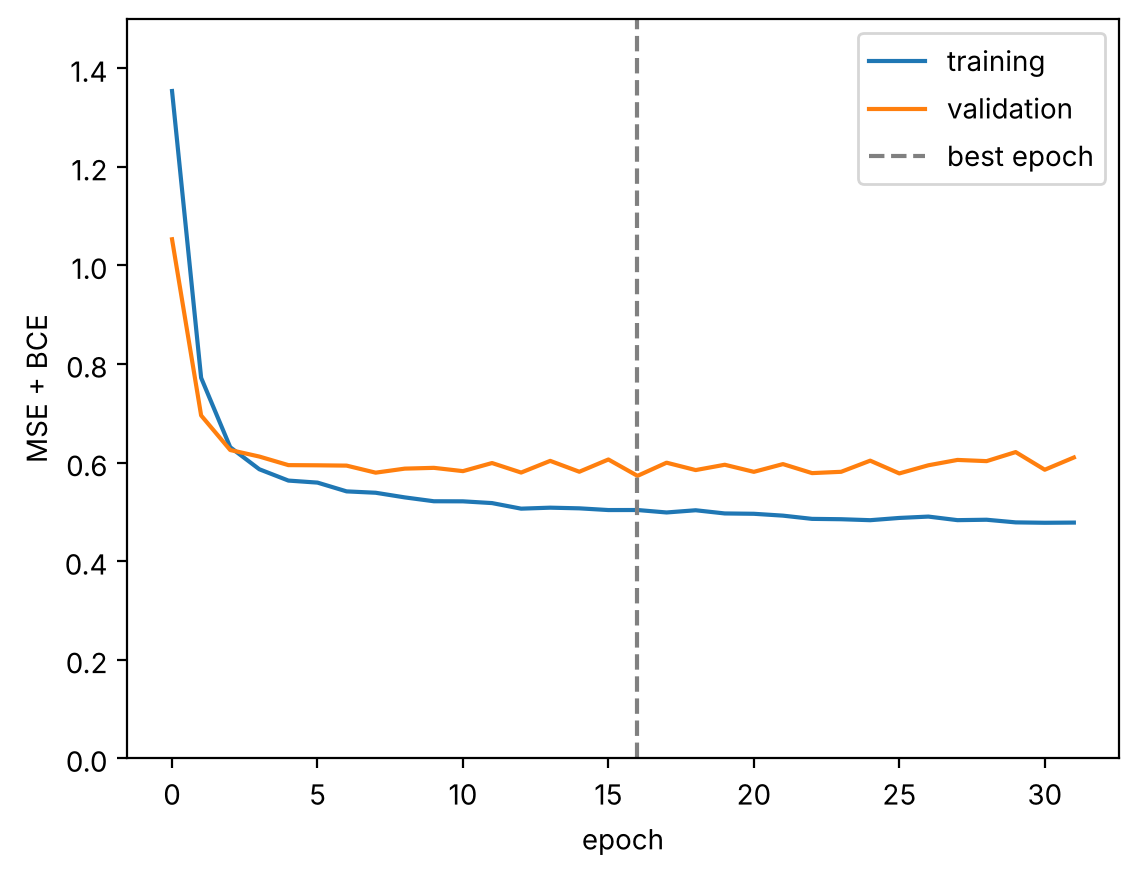

RMSE 16.4 k€ (baseline 84.4)   accuracy 0.733 (baseline 0.617)


In [19]:
torch.manual_seed(0)
net = TwoHeadMLP(X_train.shape[1])
opt = torch.optim.Adam(net.parameters(), lr=0.003)
mse_fn, bce_fn = nn.MSELoss(), nn.BCEWithLogitsLoss()
tr_hist, va_hist = [], []
best_val, best_epoch, best_state, bad = float("inf"), 0, None, 0

for epoch in range(300):
    net.train()
    losses = []
    for xb, yp, ys in loader_train:
        p, z = net(xb)
        loss = mse_fn(p, yp) + bce_fn(z, ys)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    tr_hist.append(np.mean(losses))

    net.eval()
    losses = []
    with torch.no_grad():
        for xb, yp, ys in loader_val:
            p, z = net(xb)
            losses.append((mse_fn(p, yp) + bce_fn(z, ys)).item())
    va_hist.append(np.mean(losses))

    if va_hist[-1] < best_val:
        best_val, best_epoch, bad = va_hist[-1], epoch, 0
        best_state = copy.deepcopy(net.state_dict())
    else:
        bad += 1
        if bad >= 15:
            break
net.load_state_dict(best_state)
print(f"stopped after {len(va_hist)} epochs, best epoch {best_epoch}")

plt.plot(tr_hist, label="training"); plt.plot(va_hist, label="validation"); plt.axvline(best_epoch, color="gray", ls="--", label="best epoch")
plt.ylim(0, 1.5); plt.xlabel("epoch"); plt.ylabel("MSE + BCE"); plt.legend(); plt.show()

net.eval()
with torch.no_grad():
    p, z = net(torch.tensor(X_test))
rmse = ((p[:, 0] * float(y_std) + float(y_mean) - torch.tensor(y_test)) ** 2).mean().sqrt().item()
acc = ((z[:, 0] > 0).float() == torch.tensor(s_test)).float().mean().item()
print(f"RMSE {rmse:.1f} k€ (baseline {baseline_rmse_keur:.1f})   accuracy {acc:.3f} (baseline {baseline_acc:.3f})")